In [2]:
import os
ROOT = "/Users/cathyluo/labor-market-healthcare"   
for folder in ["data", "figures", "notebooks"]:
    os.makedirs(f"{ROOT}/{folder}", exist_ok=True)
os.chdir(f"{ROOT}/notebooks")
print(os.getcwd())

/Users/cathyluo/labor-market-healthcare/notebooks


In [3]:
import pandas as pd

series = {
    "PAYEMS": "total_emp",
    "CES6562000001": "health_emp",
    "JTSJOL": "total_openings",
    "JTS6200JOL": "health_openings",
}

dfs = []
for sid, name in series.items():
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={sid}"
    s = pd.read_csv(url, index_col=0, parse_dates=True)
    s.columns = [name]
    dfs.append(s)

df = pd.concat(dfs, axis=1)
df = df.apply(pd.to_numeric, errors="coerce")  
df = df.loc["2019-01-01":]
df.to_csv("../data/raw_fred.csv")
df.tail()

,total_emp,health_emp,total_openings,health_openings
observation_date,,,,
2026-04-01,158798,23813.8,7585.0,1539.0
2026-05-01,158861,23848.6,7537.0,1494.0
2026-06-01,158892,23887.2,7182.0,1384.0
2026-07-01,158913,23900.3,7335.0,1474.0
2026-08-01,159075,23928.7,7079.0,1359.0


In [4]:
df["total_chg"] = df["total_emp"].diff()
df["health_chg"] = df["health_emp"].diff()
df["other_chg"] = df["total_chg"] - df["health_chg"]
df["other_emp"] = df["total_emp"] - df["health_emp"]

In [5]:
base = df.loc["2020-02-01"]
df["health_idx"] = df["health_emp"] / base["health_emp"] * 100
df["other_idx"] = df["other_emp"] / base["other_emp"] * 100

In [6]:
since = df.loc["2024-01-01":]
health_sum = since["health_chg"].sum()
total_sum = since["total_chg"].sum()
print(f"Health care added {health_sum:,.0f}k jobs")
print(f"Total added {total_sum:,.0f}k jobs")
print(f"Health care share: {health_sum / total_sum:.1%}")

Health care added 1,910k jobs
Total added 2,218k jobs
Health care share: 86.1%


In [7]:
df["health_open_share"] = df["health_openings"] / df["total_openings"] * 100
df["health_open_share"].dropna().tail()

observation_date
2026-04-01    20.290046
2026-05-01    19.822210
2026-06-01    19.270398
2026-07-01    20.095433
2026-08-01    19.197627
Freq: MS, Name: health_open_share, dtype: float64

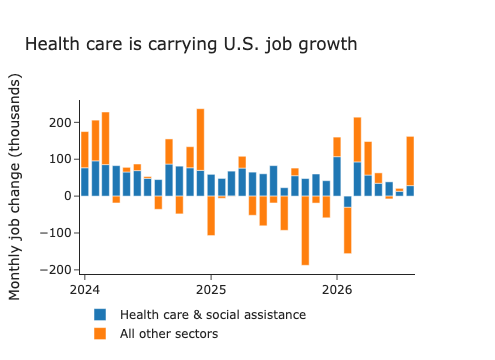

In [8]:
import plotly.graph_objects as go

d = df.loc["2024-01-01":]
fig1 = go.Figure()
fig1.add_bar(x=d.index, y=d["health_chg"], name="Health care & social assistance")
fig1.add_bar(x=d.index, y=d["other_chg"], name="All other sectors")
fig1.update_layout(
    barmode="relative",  
    title="Health care is carrying U.S. job growth",
    yaxis_title="Monthly job change (thousands)",
    template="simple_white",
    legend=dict(orientation="h", y=-0.15),
)
fig1.show()
fig1.write_image("../figures/fig1_job_change.png", scale=2, width=900, height=500)

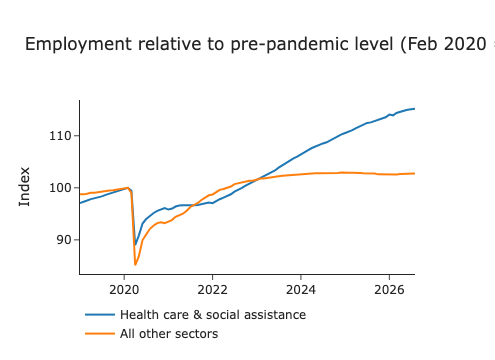

In [9]:
fig2 = go.Figure()
fig2.add_scatter(x=df.index, y=df["health_idx"], name="Health care & social assistance")
fig2.add_scatter(x=df.index, y=df["other_idx"], name="All other sectors")
fig2.add_hline(y=100, line_dash="dot", line_color="gray")
fig2.update_layout(
    title="Employment relative to pre-pandemic level (Feb 2020 = 100)",
    yaxis_title="Index",
    template="simple_white",
    legend=dict(orientation="h", y=-0.15),
)
fig2.show()
fig2.write_image("../figures/fig2_emp_index.png", scale=2, width=900, height=500)

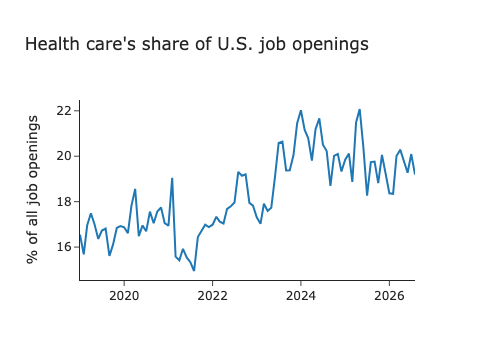

In [10]:
o = df["health_open_share"].dropna()
fig3 = go.Figure()
fig3.add_scatter(x=o.index, y=o, name="Health care share of openings")
fig3.update_layout(
    title="Health care's share of U.S. job openings",
    yaxis_title="% of all job openings",
    template="simple_white",
)
fig3.show()
fig3.write_image("../figures/fig3_openings_share.png", scale=2, width=900, height=500)